# 00 — Data audit

**Project:** Commodity calendar spreads (MTH 9897, Project 7)  
**Input:** `data/raw/bloomberg_commodity_bulk_tickers_1986_2026.csv`  
**Scope:** read-only audit. No processed panels are saved here; `01_panel_build` builds them.

The raw file contains 24 commodities × 4 generic nearby ranks (M1–M4) × 4 fields:
settlement price, volume, open interest, and the actual contract code.

This notebook answers four questions:

1. What is in the file, and what is missing?
2. How does the generic roll work?
3. Which price/volume anomalies are real?
4. How liquid is each commodity/rank, before choosing a universe threshold?


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))


In [2]:
import pandas as pd

from src import qa, viz
from src.load import load_rank_panel

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)


## 1. Load the raw file

The loader reads the six header rows, splits the 96 ticker groups, parses the real
contract code, and returns one row per `date × commodity × rank`.


In [3]:
rank = load_rank_panel()
print(f"{rank.shape[0]:,} rows × {rank.shape[1]} columns")
rank[["date", "root", "rank", "contract_code", "settle"]].head()


1,013,664 rows × 23 columns


,date,root,rank,contract_code,settle
0,1986-01-02,BO,1,BOF86,21.62
1,1986-01-02,BO,2,BOH86,21.96
2,1986-01-02,BO,3,BOK86,22.20
3,1986-01-02,BO,4,BON86,22.65
4,1986-01-02,C,1,CH86,247.50


In [4]:
rank.groupby("sector")["root"].nunique().sort_values(ascending=False)


sector
Energy         5
Grains         4
Softs          4
Livestock      3
Metals         3
Oilseeds       3
Industrials    2
Name: root, dtype: int64

The panel has 24 commodities across seven sectors. Dates with no data at all
(the 128 US market holidays) are dropped; per-commodity gaps remain visible as
missing values and are not forward-filled.


## 2. Coverage

`pct_missing` is the fraction of union trading days without a settlement for that
commodity/rank. Early listing dates and thin back months explain most gaps.


In [5]:
coverage = qa.coverage_summary(rank)
coverage.head(8)


,root,rank,first,last,n_valid,n_dates,pct_missing
0,BO,1,1986-01-02,2026-10-13,10274,10559,0.026991
1,BO,2,1986-01-02,2026-10-13,10281,10559,0.026328
2,BO,3,1986-01-02,2026-10-13,10281,10559,0.026328
3,BO,4,1986-01-02,2026-10-13,10281,10559,0.026328
4,C,1,1986-01-02,2026-10-13,10278,10559,0.026612
5,C,2,1986-01-02,2026-10-13,10280,10559,0.026423
6,C,3,1986-01-02,2026-10-13,10280,10559,0.026423
7,C,4,1986-01-02,2026-10-13,10279,10559,0.026518


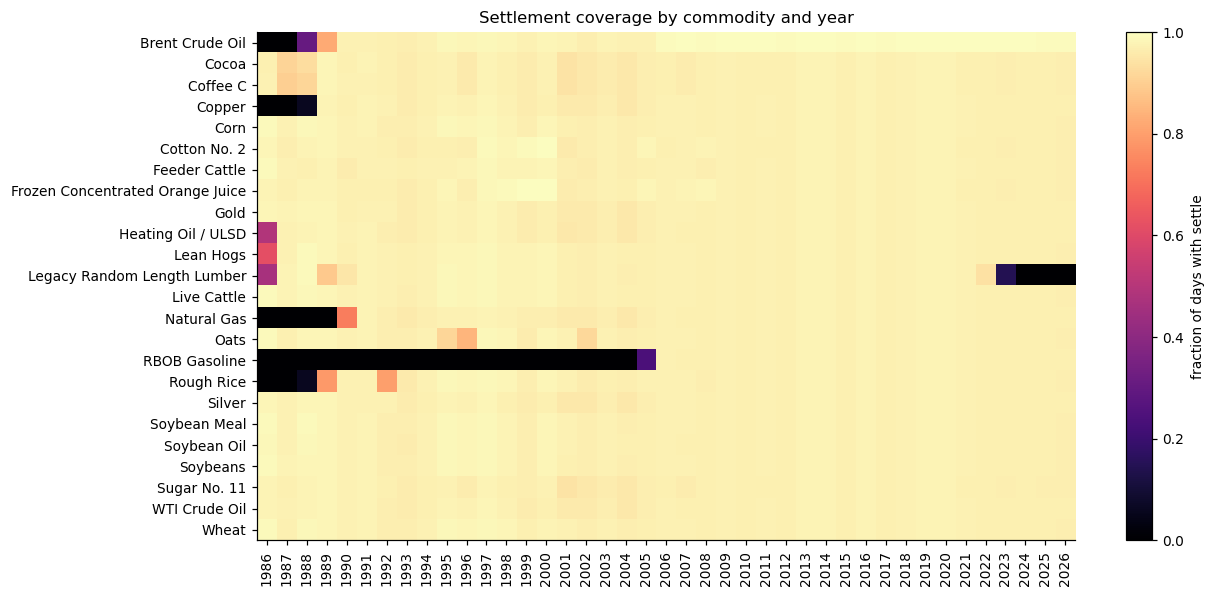

In [6]:
viz.plot_coverage_heatmap(rank);


Read the heatmap by row (commodity) and column (year). White space is missing
coverage; it is not a price of zero. XB starts in 2005, LB ends in 2023, and
CO/HG/RR/NG start later than the 1986 file start.


## 3. Roll mechanics: M1–M4 are slots, not contracts

Look at WTI around its first roll. On 1986-01-22 all four ranks shift by one
contract: the new M1 was the old M2, the new M2 was the old M3, and so on.


In [7]:
cl = rank[(rank["root"] == "CL") & rank["date"].between("1986-01-19", "1986-01-24")]
cl.pivot_table(index="date", columns="rank", values=["contract_code", "settle"], aggfunc="first")


contract_code                      settle                     
rank                   1      2      3      4      1      2      3      4
date                                                                     
1986-01-20         CLG86  CLH86  CLJ86  CLK86  21.27  21.60  20.90  20.60
1986-01-21         CLG86  CLH86  CLJ86  CLK86  20.59  20.81  20.51  20.36
1986-01-22         CLH86  CLJ86  CLK86  CLM86  20.39  20.28  20.16  20.15
1986-01-23         CLH86  CLJ86  CLK86  CLM86  19.82  19.88  20.17  20.28
1986-01-24         CLH86  CLJ86  CLK86  CLM86  19.50  19.52  19.75  19.92

The naive M1 return on the roll date mixes CLG86 and CLH86 and is not a
return. The correct return uses the new contract's previous-day price, which is
the old M2 price:

`P_CLH86(t) / P_CLH86(t-1) - 1`, not `P_CLH86(t) / P_CLG86(t-1) - 1`.

`01_panel_build` implements this mapping and shows the difference.


In [8]:
roll = qa.assert_roll_sync(rank)
{key: roll[key] for key in ["n_full_roll_dates", "n_partial_rolls", "n_full_day_violations"]}


{'n_full_roll_dates': 6377, 'n_partial_rolls': 0, 'n_full_day_violations': 0}

## 4. Data quality

The most important edge cases are contract-code gaps, missing volume/OI, stale
prices, and the one real negative settlement.


In [9]:
qa.missing_summary(rank)


,rank,n,settle_missing,code_missing,volume_missing,oi_missing
0,1,253416,16537,152,37609,45279
1,2,253416,16294,146,35128,43464
2,3,253416,16605,142,37679,43606
3,4,253416,17076,143,46777,44285


In [10]:
qa.known_events_check(rank)


{'negative_rows': 1,
 'cl_2020_04_20_present': True,
 'cl_2020_04_20_settle': -37.63,
 'expected_settle': -37.63,
 'matches_expected': True}

In [11]:
rank.loc[rank["negative_price"], ["date", "root", "rank", "contract_code", "settle"]]


,date,root,rank,contract_code,settle
852108,2020-04-20,CL,1,CLK20,-37.63


In [12]:
qa.stale_summary(rank).sort_values("max_stale_run", ascending=False).head(8)


,root,rank,stale_pct,max_stale_run
67,O,4,0.085709,14
71,RR,4,0.066862,13
19,CO,4,0.011270,8
51,LB,4,0.038735,7
69,RR,2,0.036462,6
18,CO,3,0.010134,5
70,RR,3,0.046974,5
65,O,2,0.047164,5


- 583 rows have a settlement but no contract code; they are mostly holidays
  and data outages (e.g. 2001-09-11) and cannot be aligned to a contract.
- Volume/OI are missing more often in the 1986–1990 period; missing is not zero.
- CL 2020-04-20 settled at **−37.63**. This is real; it is kept and flagged.
- Stale runs are short for M1 (max 4 sessions) and longer for some M4 contracts.


## 5. Liquidity diagnostics (no threshold chosen)

We compute trailing 252-session median volume/OI for each leg and
`pair_liquidity = min(near, far)`. The table below is diagnostic only; no
universe filter is applied yet.


In [13]:
from src.panel import build_all, liquidity_summary

panels = build_all(rank)
universe = panels["universe"]
liquidity_summary(universe)


,threshold,pair_days,pass_volume_days,pass_oi_days,roots_pass_volume,roots_pass_oi
0,1000,236186,127944,180736,20,24
1,5000,236186,69301,151137,19,21
2,10000,236186,45043,125989,13,20
3,20000,236186,27121,91569,12,20


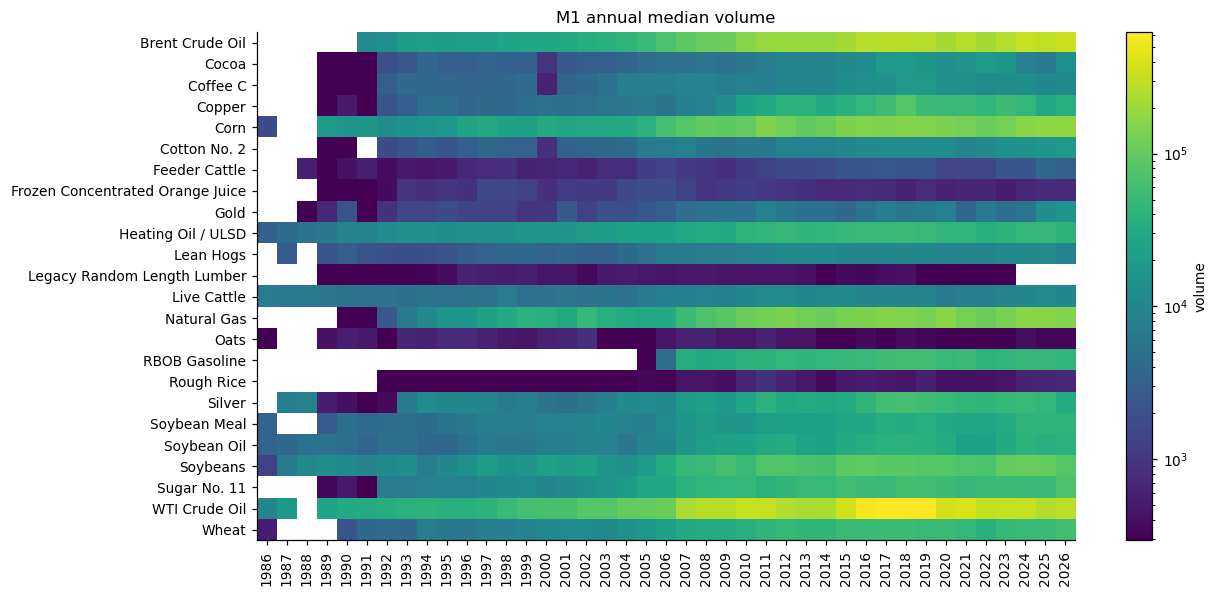

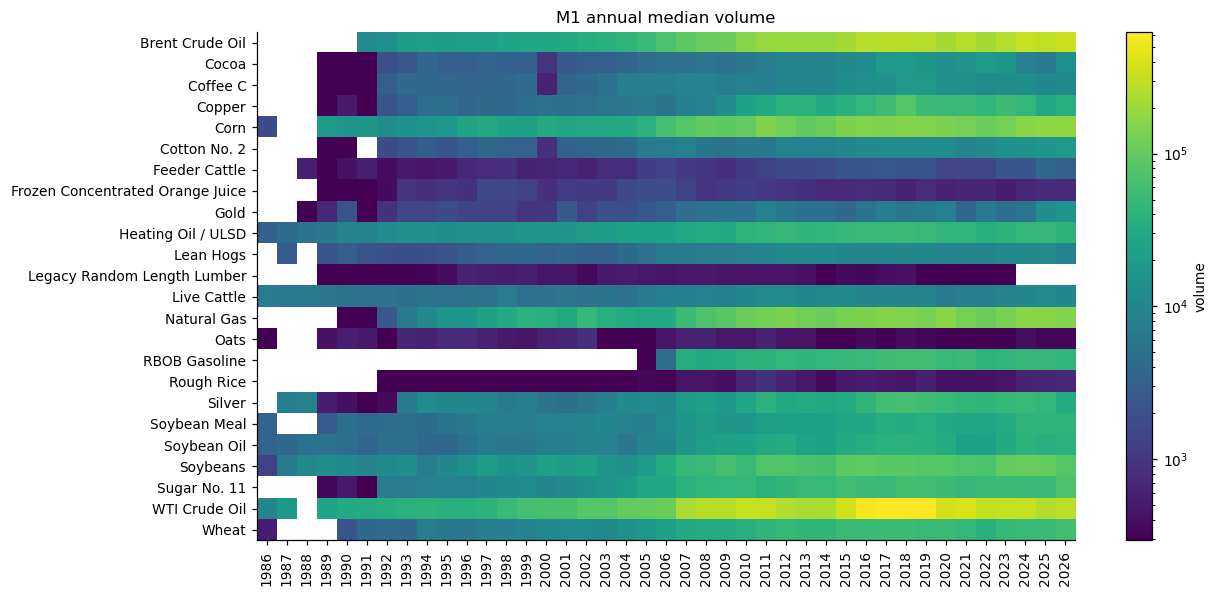

In [14]:
viz.plot_liquidity_heatmap(rank, rank=1, value="volume")


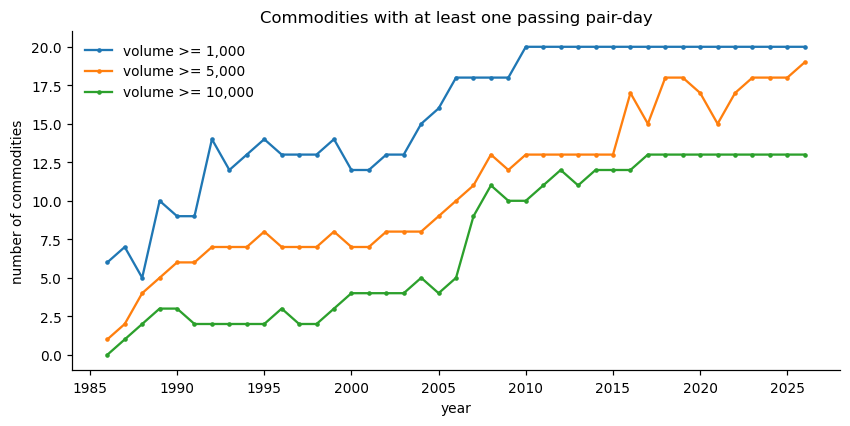

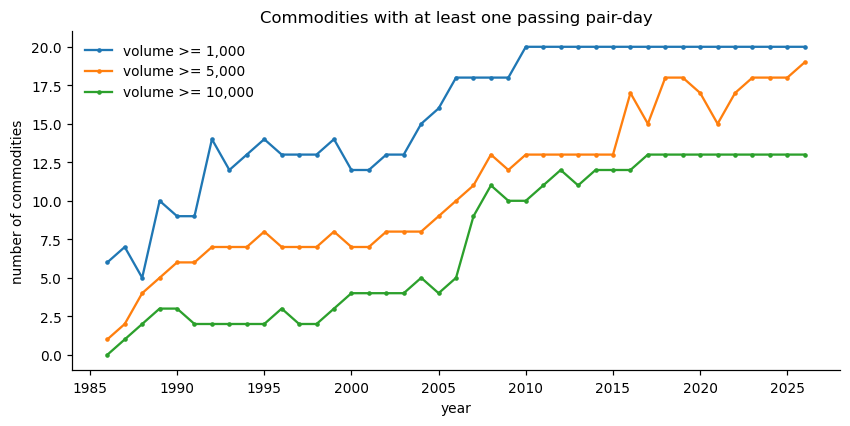

In [15]:
viz.plot_universe_counts(universe)


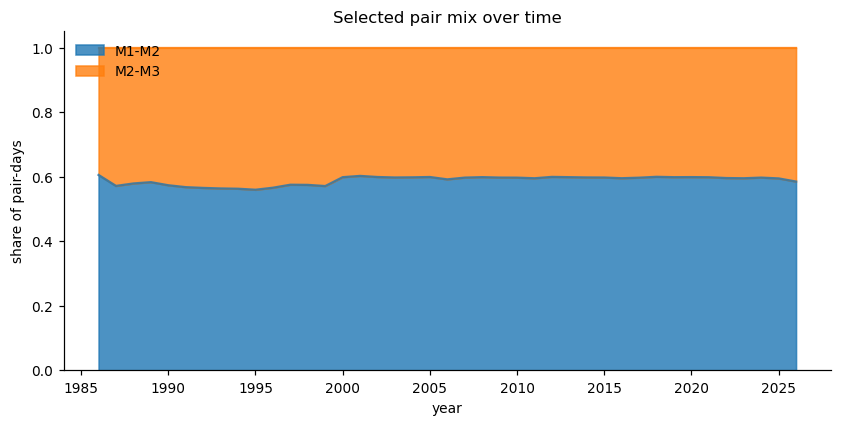

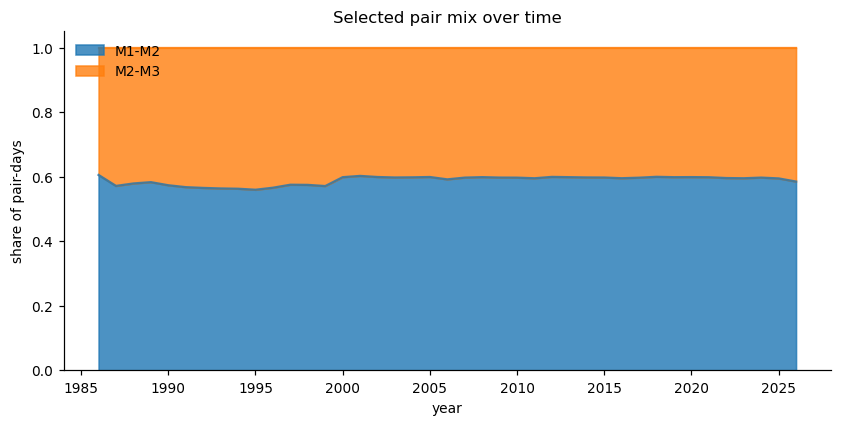

In [16]:
viz.plot_pair_mix(panels["pairs"])


A 5,000-contract trailing median leaves about 19 commodities recently, and
M2–M3 is materially thinner than M1–M2. Gold is a useful edge case: its M1 can
be less liquid than M2 near a contract roll. The final threshold is a research
choice, not a data-cleaning rule; choose it after reviewing these diagnostics.


## 6. Takeaways

- 24 commodities, 96 generic series, 10,640 weekday rows; 6,735 real contracts.
- All four ranks roll together on every full-coverage roll date; there are no
  partial-queue violations in the clean panel.
- Generic price differences across a roll are not returns. Contract-level
  mapping is the non-negotiable core of the project.
- Missing contract codes are rare and concentrated on holidays/outages; missing
  volume/OI is common early and must not be treated as zero.
- CL 2020-04-20 is a real negative settlement; log spread is undefined there.
- Liquidity is heterogeneous: choose the universe threshold after seeing the
  pair-level diagnostics.

**Next:** `01_panel_build.ipynb` builds and saves the analysis panels.
